# Are the decoys good decoys?

A decoy is useful only if it sits among the real barcodes the way real barcodes sit among each other: a misassigned read should be as likely to land on a decoy as on a real barcode. We therefore compare, for each layout, the Levenshtein distance from a **decoy** to its nearest **real** barcode with the distance from a **real** barcode to its nearest **other real** barcode. For Dual barcodes and Zipcodes, the decoys generated independently of the layout, used in the thesis, are shown for comparison.

Distances are computed for a random sample of queries against the complete set of 85,305 real barcodes.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})
import numpy as np
import pandas as pd
from rapidfuzz.distance import Levenshtein
from rapidfuzz.process import cdist

DATA = Path("../../data")
OUT_DIR = Path(".")
SAMPLE = 3000
SEED = 1

SETS = {
    "Dual barcodes": {
        "real": DATA / "1in1" / "layout_235x363_dual_4x4.txt",
        "Structure-matched decoys": DATA / "decoys" / "output" / "dual" / "dual_decoys.txt",
        "Independent decoys (thesis)": DATA / "decoy_layouts" / "barcodes" / "1in1" / "layout_235x363_dual_4x4.txt",
    },
    "Zipcodes": {
        "real": DATA / "1in1" / "layout_235x363_zipcodes_nosep.txt",
        "Structure-matched decoys": DATA / "decoys" / "output" / "zipcodes_balanced_khalf" / "zip_decoysv2.txt",
        "Independent decoys (thesis)": DATA / "decoy_layouts" / "barcodes" / "1in1" / "layout_235x363_zipcodes_nosep.txt",
    },
    "Greedy + 2-OPT": {
        "real": DATA / "1in1" / "layout_235x363_randombarcodes_opt.txt",
        # all 85,305 entries of this file are in the combined whitelist used for decoding
        "Unplaced pool barcodes (decoys)": DATA / "decoy_layouts" / "barcodes" / "1in1" / "greedy_decoybar_1in1_column_major.txt",
    },
}

In [2]:
def read_seqs(path):
    with open(path) as handle:
        return [line.strip().upper() for line in handle if line.strip()]


def nearest_distance(queries, refs, exclude_self=False, batch=250):
    out = []
    for i in range(0, len(queries), batch):
        d = cdist(queries[i:i + batch], refs, scorer=Levenshtein.distance, dtype=np.int32, workers=-1)
        if exclude_self:
            d[d == 0] = np.iinfo(np.int32).max
        out.append(d.min(axis=1))
    return np.concatenate(out)


rng = np.random.default_rng(SEED)
distances, summary = {}, []
for layout, files in SETS.items():
    real = read_seqs(files["real"])
    real_set = set(real)
    assert len(real_set) == len(real)
    q = [real[i] for i in rng.choice(len(real), SAMPLE, replace=False)]
    distances[(layout, "Real to nearest other real")] = nearest_distance(q, real, exclude_self=True)
    for label, path in files.items():
        if label == "real":
            continue
        if not path.exists():
            print(f"{layout}: {path} not found, skipped")
            continue
        decoys = [s for s in dict.fromkeys(read_seqs(path)) if s not in real_set]
        q = [decoys[i] for i in rng.choice(len(decoys), min(SAMPLE, len(decoys)), replace=False)]
        distances[(layout, f"{label} to nearest real")] = nearest_distance(q, real)

for (layout, label), d in distances.items():
    summary.append({"layout": layout, "distribution": label, "n": len(d), "min": d.min(),
                    "median": np.median(d), "mean": round(d.mean(), 2), "max": d.max()})
summary = pd.DataFrame(summary).set_index(["layout", "distribution"])
summary.to_csv(OUT_DIR / "decoy_nearest_real_levenshtein.csv")
summary

n  min  \
layout         distribution                                                 
Dual barcodes  Real to nearest other real                       3000    3   
               Structure-matched decoys to nearest real         3000    4   
               Independent decoys (thesis) to nearest real      3000    9   
Zipcodes       Real to nearest other real                       3000    4   
               Structure-matched decoys to nearest real         3000    4   
               Independent decoys (thesis) to nearest real      3000   10   
Greedy + 2-OPT Real to nearest other real                       3000    8   
               Unplaced pool barcodes (decoys) to nearest real  3000    9   

                                                                median   mean  \
layout         distribution                                                     
Dual barcodes  Real to nearest other real                          8.0   8.21   
               Structure-matched decoys to nearest real            8.0   8.16   
               Independent decoys (thesis) to nearest real        12.0  11.79   
Zipcodes       Real to nearest other real                          5.0   5.30   
               Structure-matched decoys to nearest real            6.0   6.15   
               Independent decoys (thesis) to nearest real        13.0  13.00   
Greedy + 2-OPT Real to nearest other real                         12.0  11.73   
               Unplaced pool barcodes (decoys) to nearest real    12.0  11.68   

                                                                max  
layout         distribution                                          
Dual barcodes  Real to nearest other real                        11  
               Structure-matched decoys to nearest real          11  
               Independent decoys (thesis) to nearest real       14  
Zipcodes       Real to nearest other real                         8  
               Structure-matched decoys to nearest real           8  
               Independent decoys (thesis) to nearest real       16  
Greedy + 2-OPT Real to nearest other real                        13  
               Unplaced pool barcodes (decoys) to nearest real   13

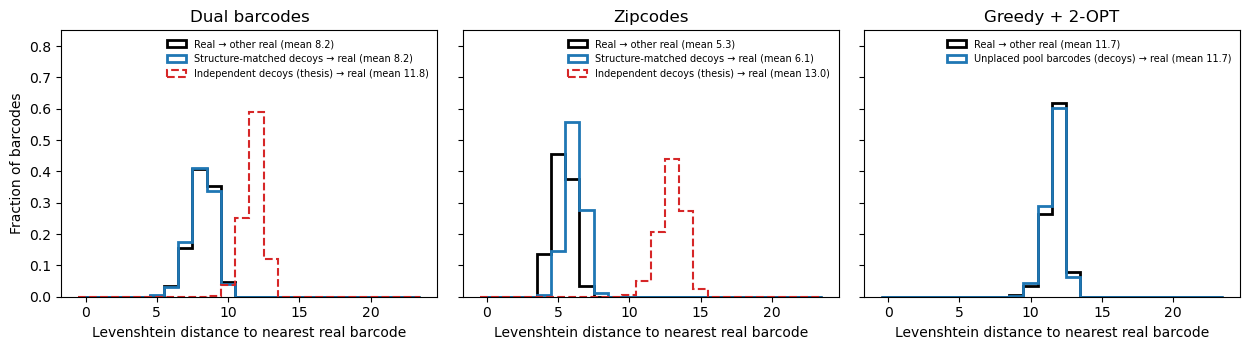

In [3]:
STYLE = {
    "Real to nearest other real": dict(color="black", lw=2),
    "Structure-matched decoys to nearest real": dict(color="tab:blue", lw=2),
    "Unplaced pool barcodes (decoys) to nearest real": dict(color="tab:blue", lw=2),
    "Independent decoys (thesis) to nearest real": dict(color="tab:red", lw=1.5, ls="--"),
}
layouts = list(SETS)
fig, axes = plt.subplots(1, len(layouts), figsize=(4.2 * len(layouts), 3.6), sharey=True)
bins = np.arange(0, 25) - 0.5
for ax, layout in zip(axes, layouts):
    for (lay, label), d in distances.items():
        if lay != layout:
            continue
        ax.hist(d, bins=bins, density=True, histtype="step",
                label=f"{label.replace(' to nearest', ' →').replace('nearest other real', 'nearest real')} (mean {d.mean():.1f})",
                **STYLE[label])
    ax.set_title(layout)
    ax.set_ylim(0, 0.85)
    ax.set_xlabel("Levenshtein distance to nearest real barcode")
    ax.legend(frameon=False, fontsize=7, loc="upper right")
axes[0].set_ylabel("Fraction of barcodes")
fig.tight_layout()
fig.savefig(OUT_DIR / "decoy_nearest_real_levenshtein.pdf")
fig.savefig(OUT_DIR / "decoy_nearest_real_levenshtein.png", dpi=200)
plt.show()